# Part A: Numerical Data

## Exploratory Data Analysis (EDA)

Dataset: CarDekho Vehicle Dataset

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
df = pd.read_csv('data/Car details v3.csv')

print('Dataset loaded successfully!')
print(f'Shape: {df.shape}')

Dataset loaded successfully!
Shape: (8128, 13)


In [49]:
print("display the first 10 rows:")
display(df.head(10))
print("\ndata types and non null counts:")
df.info()
print("\nidentify which columns have missing values and how many:")
print(df.isna().sum())

display the first 10 rows:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0
5,Hyundai Xcent 1.2 VTVT E Plus,2017,440000,45000,Petrol,Individual,Manual,First Owner,20.14 kmpl,1197 CC,81.86 bhp,113.75nm@ 4000rpm,5.0
6,Maruti Wagon R LXI DUO BSIII,2007,96000,175000,LPG,Individual,Manual,First Owner,17.3 km/kg,1061 CC,57.5 bhp,"7.8@ 4,500(kgm@ rpm)",5.0
7,Maruti 800 DX BSII,2001,45000,5000,Petrol,Individual,Manual,Second Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0
8,Toyota Etios VXD,2011,350000,90000,Diesel,Individual,Manual,First Owner,23.59 kmpl,1364 CC,67.1 bhp,170Nm@ 1800-2400rpm,5.0
9,Ford Figo Diesel Celebration Edition,2013,200000,169000,Diesel,Individual,Manual,First Owner,20.0 kmpl,1399 CC,68.1 bhp,160Nm@ 2000rpm,5.0



data types and non null counts:
<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB

identify which columns have missing values and how many:
name               0
year               0
selling_price      0
km_driven          0
fuel     

In [50]:
print("\npercentage of missing values for each column:")
print((df.isna().sum() / len(df) * 100).round(2))
print("\nsummary showing only columns with missing values:")
print(df.isna().sum()[df.isna().sum() > 0])
print(f"column has the most missing values: {df.isna().sum().idxmax()} with {((df.isna().sum().max()) / len(df) * 100).round(2)}% percent of missing values")


percentage of missing values for each column:
name             0.00
year             0.00
selling_price    0.00
km_driven        0.00
fuel             0.00
seller_type      0.00
transmission     0.00
owner            0.00
mileage          2.72
engine           2.72
max_power        2.65
torque           2.73
seats            2.72
dtype: float64

summary showing only columns with missing values:
mileage      221
engine       221
max_power    215
torque       222
seats        221
dtype: int64
column has the most missing values: torque with 2.73% percent of missing values


In [51]:
print("\nduplicate rows in the dataset:")
print(df.duplicated())
print("\nHow many duplicate rows exist?", df.duplicated().sum())
print("\nduplicate rows in the dataset:")
display(df[df.duplicated()].head(10))


duplicate rows in the dataset:
0       False
1       False
2       False
3       False
4       False
        ...  
8123    False
8124    False
8125    False
8126     True
8127     True
Length: 8128, dtype: bool

How many duplicate rows exist? 1202

duplicate rows in the dataset:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
291,Hyundai Grand i10 Sportz,2017,450000,35000,Petrol,Individual,Manual,First Owner,18.9 kmpl,1197 CC,82 bhp,114Nm@ 4000rpm,5.0
296,Maruti Swift VXI,2012,330000,50000,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,85.8 bhp,114Nm@ 4000rpm,5.0
370,Jaguar XE 2016-2019 2.0L Diesel Prestige,2017,2625000,9000,Diesel,Dealer,Automatic,First Owner,13.6 kmpl,1999 CC,177 bhp,430Nm@ 1750-2500rpm,5.0
371,Lexus ES 300h,2019,5150000,20000,Petrol,Dealer,Automatic,First Owner,22.37 kmpl,2487 CC,214.56 bhp,202Nm@ 3600-5200rpm,5.0
372,Jaguar XF 2.0 Diesel Portfolio,2017,3200000,45000,Diesel,Dealer,Automatic,First Owner,19.33 kmpl,1999 CC,177 bhp,430Nm@ 1750-2500rpm,5.0
387,Skoda Rapid 1.6 MPI AT Elegance,2016,645000,11000,Petrol,Dealer,Automatic,First Owner,14.3 kmpl,1598 CC,103.5 bhp,153Nm@ 3800rpm,5.0
409,Jaguar XE 2016-2019 2.0L Diesel Prestige,2017,2625000,9000,Diesel,Dealer,Automatic,First Owner,13.6 kmpl,1999 CC,177 bhp,430Nm@ 1750-2500rpm,5.0
410,Lexus ES 300h,2019,5150000,20000,Petrol,Dealer,Automatic,First Owner,22.37 kmpl,2487 CC,214.56 bhp,202Nm@ 3600-5200rpm,5.0
411,Jaguar XF 2.0 Diesel Portfolio,2017,3200000,45000,Diesel,Dealer,Automatic,First Owner,19.33 kmpl,1999 CC,177 bhp,430Nm@ 1750-2500rpm,5.0
412,Tata Safari Storme EX,2015,503000,110000,Diesel,Individual,Manual,First Owner,14.1 kmpl,2179 CC,147.94 bhp,320Nm@ 1500-3000rpm,7.0


In [52]:
missing_cols = df.isna().sum()[df.isna().sum() > 0]
print(df[missing_cols.index].dtypes)
display(df[missing_cols.index].head(20))
display(df[missing_cols.index].describe())

mileage          str
engine           str
max_power        str
torque           str
seats        float64
dtype: object


,mileage,engine,max_power,torque,seats
0,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0
5,20.14 kmpl,1197 CC,81.86 bhp,113.75nm@ 4000rpm,5.0
6,17.3 km/kg,1061 CC,57.5 bhp,"7.8@ 4,500(kgm@ rpm)",5.0
7,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0
8,23.59 kmpl,1364 CC,67.1 bhp,170Nm@ 1800-2400rpm,5.0
9,20.0 kmpl,1399 CC,68.1 bhp,160Nm@ 2000rpm,5.0


,seats
count,7907.000000
mean,5.416719
std,0.959588
min,2.000000
25%,5.000000
50%,5.000000
75%,5.000000
max,14.000000


In [53]:
display(df.describe())

,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


In [54]:
columns = ['year', 'selling_price', 'km_driven']
for col in columns:
    rate = df[col]
    q1 = rate.quantile(0.25)
    q3 = rate.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    print(col)
    print("Lower bound:", lower)
    print("Upper bound:", upper)
    print("How many outliers exist?", ((rate < lower) | (rate > upper)).sum())
    display(df[((rate < lower) | (rate > upper))])

year
Lower bound: 2002.0
Upper bound: 2026.0
How many outliers exist? 81


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
7,Maruti 800 DX BSII,2001,45000,5000,Petrol,Individual,Manual,Second Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0
177,Maruti 800 Std,1999,40000,40000,Petrol,Individual,Manual,Second Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0
186,Daewoo Matiz SD,2000,100000,60000,Petrol,Individual,Manual,First Owner,18.5 kmpl,796 CC,53 bhp,71Nm@ 3500rpm,5.0
316,Mahindra Willys CJ 3B 4X4,1983,300000,10000,Diesel,Individual,Manual,Third Owner,NaN,NaN,NaN,NaN,NaN
774,Hyundai Santro GLS I - Euro I,1999,80000,110000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7982,Maruti Alto LX,2000,45957,90000,Petrol,Individual,Manual,Second Owner,19.7 kmpl,796 CC,46.3 bhp,62Nm@ 3000rpm,5.0
7996,Hyundai Santro LS zipPlus,2000,140000,50000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
8025,Maruti 800 AC,1998,35000,40000,Petrol,Individual,Manual,Second Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0
8042,Maruti Gypsy King Soft Top,1997,300000,186388,Petrol,Individual,Manual,Second Owner,14.8 kmpl,1298 CC,80 bhp,103Nm@ 4500rpm,8.0


selling_price
Lower bound: -375002.5
Upper bound: 1305001.5
How many outliers exist? 600


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
41,Jeep Compass 1.4 Limited Plus BSIV,2019,2100000,5000,Petrol,Individual,Automatic,First Owner,16.0 kmpl,1368 CC,160.77 bhp,250Nm@ 1750-2500rpm,5.0
47,Toyota Fortuner 4x4 MT,2014,1500000,77000,Diesel,Dealer,Manual,First Owner,12.55 kmpl,2982 CC,168.5 bhp,343Nm@ 1400-3400rpm,7.0
49,Mercedes-Benz B Class B180,2014,1450000,27800,Diesel,Dealer,Automatic,Second Owner,14.8 kmpl,2143 CC,120.7 bhp,200Nm@ 1250-4000rpm,5.0
55,Toyota Innova Crysta 2.8 ZX AT BSIV,2016,1650000,127700,Diesel,Dealer,Automatic,Second Owner,11.36 kmpl,2755 CC,171.5 bhp,360Nm@ 1200-3400rpm,7.0
57,Audi A6 2.0 TDI Technology,2013,1750000,33900,Diesel,Dealer,Automatic,Second Owner,17.68 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7949,Toyota Innova 2.5 ZX Diesel 7 Seater BSIII,2015,1400000,170000,Diesel,Individual,Manual,First Owner,12.99 kmpl,2494 CC,100.6 bhp,200Nm@ 1400-3400rpm,7.0
7967,BMW 3 Series 320d Sedan,2011,1500000,84925,Diesel,Individual,Automatic,First Owner,16.07 kmpl,1995 CC,181 bhp,380Nm@ 1750-3000rpm,5.0
7973,Toyota Innova 2.5 ZX Diesel 7 Seater BSIII,2015,1400000,170000,Diesel,Individual,Manual,First Owner,12.99 kmpl,2494 CC,100.6 bhp,200Nm@ 1400-3400rpm,7.0
8058,Audi A3 40 TFSI Premium,2017,1689999,8000,Petrol,Dealer,Automatic,First Owner,16.6 kmpl,1798 CC,177.5 bhp,250Nm@ 1250-5000rpm,5.0


km_driven
Lower bound: -59500.0
Upper bound: 192500.0
How many outliers exist? 170


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
272,Maruti Swift Dzire ZDi,2012,320000,193000,Diesel,Individual,Manual,First Owner,19.3 kmpl,1248 CC,73.9 bhp,190Nm@ 2000rpm,5.0
287,Mahindra Bolero DI DX 7 Seater,2007,210000,207890,Diesel,Individual,Manual,Second Owner,13.6 kmpl,2523 CC,63 bhp,180 Nm at 1440-1500rpm,7.0
394,Toyota Innova 2.5 G1 Diesel 8-seater,2005,250000,240000,Diesel,Individual,Manual,Third Owner,12.8 kmpl,2494 CC,102 bhp,20.4@ 1400-3400(kgm@ rpm),8.0
396,Hyundai Verna XXi ABS (Petrol),2009,340000,214000,Petrol,Individual,Manual,Second Owner,13.9 kmpl,1599 CC,103.2 bhp,"14.9@ 3,000(kgm@ rpm)",5.0
397,Hyundai Verna CRDi SX,2009,340000,214000,Diesel,Individual,Manual,Second Owner,16.8 kmpl,1493 CC,110 bhp,"24@ 1,900-2,750(kgm@ rpm)",5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8031,Chevrolet Enjoy TCDi LT 7 Seater,2014,275000,195000,Diesel,Individual,Manual,First Owner,18.2 kmpl,1248 CC,73.8 bhp,172.5Nm@ 1750rpm,7.0
8033,Hyundai Verna 1.6 SX,2012,450000,200000,Diesel,Individual,Manual,Second Owner,22.32 kmpl,1582 CC,126.32 bhp,259.8Nm@ 1900-2750rpm,5.0
8071,Toyota Innova 2.5 V Diesel 7-seater,2010,425000,200000,Diesel,Individual,Manual,Second Owner,12.8 kmpl,2494 CC,102 bhp,20.4@ 1400-3400(kgm@ rpm),7.0
8077,Toyota Innova 2.5 E 7 STR,2009,550000,250000,Diesel,Individual,Manual,First Owner,12.8 kmpl,2494 CC,102 bhp,20.4@ 1400-3400(kgm@ rpm),7.0


In [55]:
df['seats'].value_counts()

seats
5.0     6254
7.0     1120
8.0      236
4.0      133
9.0       80
6.0       62
10.0      19
2.0        2
14.0       1
Name: count, dtype: int64

In [56]:
display(df[df['seats'] == 14])

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
4575,Tata Winger Deluxe - Flat Roof (Non-AC),2010,235000,50000,Diesel,Individual,Manual,First Owner,10.71 kmpl,1948 CC,90 bhp,190Nm@ 2000-3000rpm,14.0


In [57]:
columns_str = df.select_dtypes(include='str').columns
for col in columns_str:
    print(df[col].value_counts())

name
Maruti Swift Dzire VDI                          129
Maruti Alto 800 LXI                              82
Maruti Alto LXi                                  71
BMW X4 M Sport X xDrive20d                       62
Maruti Swift VDI                                 61
                                               ... 
Maruti Celerio ZXI AMT BSIV                       1
Tata Bolt Revotron XM                             1
Tata Manza Aura (ABS) Safire BS IV                1
Tata Nexon 1.5 Revotorq XT                        1
Toyota Innova 2.5 GX (Diesel) 8 Seater BS IV      1
Name: count, Length: 2058, dtype: int64
fuel
Diesel    4402
Petrol    3631
CNG         57
LPG         38
Name: count, dtype: int64
seller_type
Individual          6766
Dealer              1126
Trustmark Dealer     236
Name: count, dtype: int64
transmission
Manual       7078
Automatic    1050
Name: count, dtype: int64
owner
First Owner             5289
Second Owner            2105
Third Owner              555
Fourth & Ab

In [64]:
df["torque"].unique().tolist()

['190Nm@ 2000rpm',
 '250Nm@ 1500-2500rpm',
 '12.7@ 2,700(kgm@ rpm)',
 '22.4 kgm at 1750-2750rpm',
 '11.5@ 4,500(kgm@ rpm)',
 '113.75nm@ 4000rpm',
 '7.8@ 4,500(kgm@ rpm)',
 '59Nm@ 2500rpm',
 '170Nm@ 1800-2400rpm',
 '160Nm@ 2000rpm',
 '248Nm@ 2250rpm',
 '78Nm@ 4500rpm',
 nan,
 '84Nm@ 3500rpm',
 '115Nm@ 3500-3600rpm',
 '200Nm@ 1750rpm',
 '62Nm@ 3000rpm',
 '219.7Nm@ 1500-2750rpm',
 '114Nm@ 3500rpm',
 '115Nm@ 4000rpm',
 '69Nm@ 3500rpm',
 '172.5Nm@ 1750rpm',
 '6.1kgm@ 3000rpm',
 '114.7Nm@ 4000rpm',
 '60Nm@ 3500rpm',
 '90Nm@ 3500rpm',
 '151Nm@ 4850rpm',
 '104Nm@ 4000rpm',
 '320Nm@ 1700-2700rpm',
 '250Nm@ 1750-2500rpm',
 '145Nm@ 4600rpm',
 '146Nm@ 4800rpm',
 '343Nm@ 1400-3400rpm',
 '200Nm@ 1400-3400rpm',
 '200Nm@ 1250-4000rpm',
 '400Nm@ 2000-2500rpm',
 '138Nm@ 4400rpm',
 '360Nm@ 1200-3400rpm',
 '200Nm@ 1200-3600rpm',
 '380Nm@ 1750-2500rpm',
 '173Nm@ 4000rpm',
 '400Nm@ 1750-3000rpm',
 '400Nm@ 1400-2800rpm',
 '200Nm@ 1750-3000rpm',
 '111.7Nm@ 4000rpm',
 '219.6Nm@ 1500-2750rpm',
 '112Nm@ 4000rpm'

In [59]:
df_eda = df.copy()
df_eda['engine'] = pd.to_numeric(df_eda['engine'].str.replace('CC', '').str.strip())
df_eda['max_power'] = pd.to_numeric(df_eda['max_power'].str.replace('bhp', '').str.strip())
df_eda['mileage_unit'] = df_eda['mileage'].str.split().str[1]
df_eda['mileage'] = pd.to_numeric(df_eda['mileage'].str.split().str[0])
df_eda.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   float64
 9   engine         7907 non-null   float64
 10  max_power      7912 non-null   float64
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
 13  mileage_unit   7907 non-null   object 
dtypes: float64(4), int64(3), object(1), str(6)
memory usage: 889.1+ KB


In [60]:
display(df_eda.describe())

,year,selling_price,km_driven,mileage,engine,max_power,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000,7907.000000,7912.000000,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,19.418783,1458.625016,91.517919,5.416719
std,4.044249,8.062534e+05,5.655055e+04,4.037145,503.916303,35.822499,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,0.000000,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,16.780000,1197.000000,68.050000,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,19.300000,1248.000000,82.000000,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,22.320000,1582.000000,102.000000,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,400.000000,14.000000


In [61]:
columns = ['mileage', 'engine', 'max_power']
for col in columns:
    rate = df_eda[col]
    q1 = rate.quantile(0.25)
    q3 = rate.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    print(col)
    print("Lower bound:", lower)
    print("Upper bound:", upper)
    print("How many outliers exist?", ((rate < lower) | (rate > upper)).sum())
    display(df_eda[((rate < lower) | (rate > upper))])

mileage
Lower bound: 8.470000000000002
Upper bound: 30.63
How many outliers exist? 24


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,mileage_unit
35,Maruti Alto 800 CNG LXI Optional,2019,330000,10000,CNG,Individual,Manual,Second Owner,33.44,796.0,40.30,60Nm@ 3500rpm,4.0,km/kg
170,Volvo XC90 T8 Excellence BSIV,2017,10000000,30000,Petrol,Individual,Automatic,First Owner,42.00,1969.0,400.00,640Nm@ 1740rpm,4.0,kmpl
644,Tata Indica Vista Aura Safire Anniversary Edition,2009,135000,28900,Petrol,Individual,Manual,Second Owner,0.00,1172.0,65.00,"9.8@ 3,000(kgm@ rpm)",5.0,kmpl
785,Hyundai Santro Xing GL,2009,120000,90000,Petrol,Individual,Manual,Second Owner,0.00,1086.0,62.00,96.1Nm@ 3000rpm,5.0,kmpl
1649,Hyundai Santro Xing GL,2008,105000,128000,Petrol,Individual,Manual,First Owner,0.00,1086.0,62.00,96.1Nm@ 3000rpm,5.0,kmpl
1676,Mercedes-Benz M-Class ML 350 4Matic,2011,1700000,110000,Diesel,Individual,Automatic,Third Owner,0.00,2987.0,165.00,510@ 1600-2400,5.0,kmpl
2137,Land Rover Freelander 2 TD4 HSE,2013,1650000,64788,Diesel,Dealer,Automatic,First Owner,0.00,2179.0,115.00,400 Nm /2000 rpm,5.0,kmpl
2312,Maruti Wagon R CNG LXI,2013,270000,80000,CNG,Individual,Manual,Second Owner,32.52,998.0,58.33,78Nm@ 3500rpm,5.0,km/kg
2366,Hyundai Santro Xing (Non-AC),2010,110000,80000,Petrol,Individual,Manual,Second Owner,0.00,1086.0,62.10,96.1Nm@ 3000rpm,5.0,kmpl
2725,Hyundai Santro Xing (Non-AC),2013,184000,15000,Petrol,Individual,Manual,First Owner,0.00,1086.0,62.10,96.1Nm@ 3000rpm,5.0,kmpl


engine
Lower bound: 619.5
Upper bound: 2159.5
How many outliers exist? 1183


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,mileage_unit
39,Tata Safari DICOR 2.2 LX 4x2,2011,425000,60000,Diesel,Individual,Manual,Second Owner,13.93,2179.0,138.03,320Nm@ 1700-2700rpm,7.0,kmpl
47,Toyota Fortuner 4x4 MT,2014,1500000,77000,Diesel,Dealer,Manual,First Owner,12.55,2982.0,168.50,343Nm@ 1400-3400rpm,7.0,kmpl
48,Toyota Innova 2.5 G (Diesel) 7 Seater BS IV,2013,700000,99000,Diesel,Dealer,Manual,First Owner,12.99,2494.0,100.00,200Nm@ 1400-3400rpm,7.0,kmpl
51,Mitsubishi Pajero Sport 4X4,2013,1090000,151000,Diesel,Dealer,Manual,First Owner,13.50,2477.0,175.56,400Nm@ 2000-2500rpm,7.0,kmpl
55,Toyota Innova Crysta 2.8 ZX AT BSIV,2016,1650000,127700,Diesel,Dealer,Automatic,Second Owner,11.36,2755.0,171.50,360Nm@ 1200-3400rpm,7.0,kmpl
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8071,Toyota Innova 2.5 V Diesel 7-seater,2010,425000,200000,Diesel,Individual,Manual,Second Owner,12.80,2494.0,102.00,20.4@ 1400-3400(kgm@ rpm),7.0,kmpl
8077,Toyota Innova 2.5 E 7 STR,2009,550000,250000,Diesel,Individual,Manual,First Owner,12.80,2494.0,102.00,20.4@ 1400-3400(kgm@ rpm),7.0,kmpl
8080,Tata New Safari DICOR 2.2 EX 4x2,2010,300000,100000,Diesel,Individual,Manual,First Owner,11.57,2179.0,138.10,320Nm@ 1700-2700rpm,7.0,kmpl
8099,Mahindra XUV500 W8 2WD,2013,750000,120000,Diesel,Individual,Manual,First Owner,15.10,2179.0,140.00,330Nm@ 1600-2800rpm,7.0,kmpl


max_power
Lower bound: 17.124999999999993
Upper bound: 152.925
How many outliers exist? 570


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,mileage_unit
41,Jeep Compass 1.4 Limited Plus BSIV,2019,2100000,5000,Petrol,Individual,Automatic,First Owner,16.00,1368.0,160.77,250Nm@ 1750-2500rpm,5.0,kmpl
47,Toyota Fortuner 4x4 MT,2014,1500000,77000,Diesel,Dealer,Manual,First Owner,12.55,2982.0,168.50,343Nm@ 1400-3400rpm,7.0,kmpl
51,Mitsubishi Pajero Sport 4X4,2013,1090000,151000,Diesel,Dealer,Manual,First Owner,13.50,2477.0,175.56,400Nm@ 2000-2500rpm,7.0,kmpl
55,Toyota Innova Crysta 2.8 ZX AT BSIV,2016,1650000,127700,Diesel,Dealer,Automatic,Second Owner,11.36,2755.0,171.50,360Nm@ 1200-3400rpm,7.0,kmpl
57,Audi A6 2.0 TDI Technology,2013,1750000,33900,Diesel,Dealer,Automatic,Second Owner,17.68,1968.0,174.33,380Nm@ 1750-2500rpm,5.0,kmpl
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7967,BMW 3 Series 320d Sedan,2011,1500000,84925,Diesel,Individual,Automatic,First Owner,16.07,1995.0,181.00,380Nm@ 1750-3000rpm,5.0,kmpl
8023,Hyundai Santa Fe 4x4 AT,2011,1200000,62000,Diesel,Individual,Automatic,Second Owner,11.72,2199.0,194.30,436.4Nm@ 1800-2500rpm,7.0,kmpl
8052,Honda CR-V 2.4L 4WD AT,2012,750000,50171,Petrol,Dealer,Automatic,First Owner,11.10,2354.0,158.80,218Nm@ 4200rpm,5.0,kmpl
8057,Honda Accord 2.4 A/T,2013,580000,50000,Petrol,Dealer,Automatic,First Owner,11.70,2354.0,177.60,222Nm@ 4300rpm,5.0,kmpl


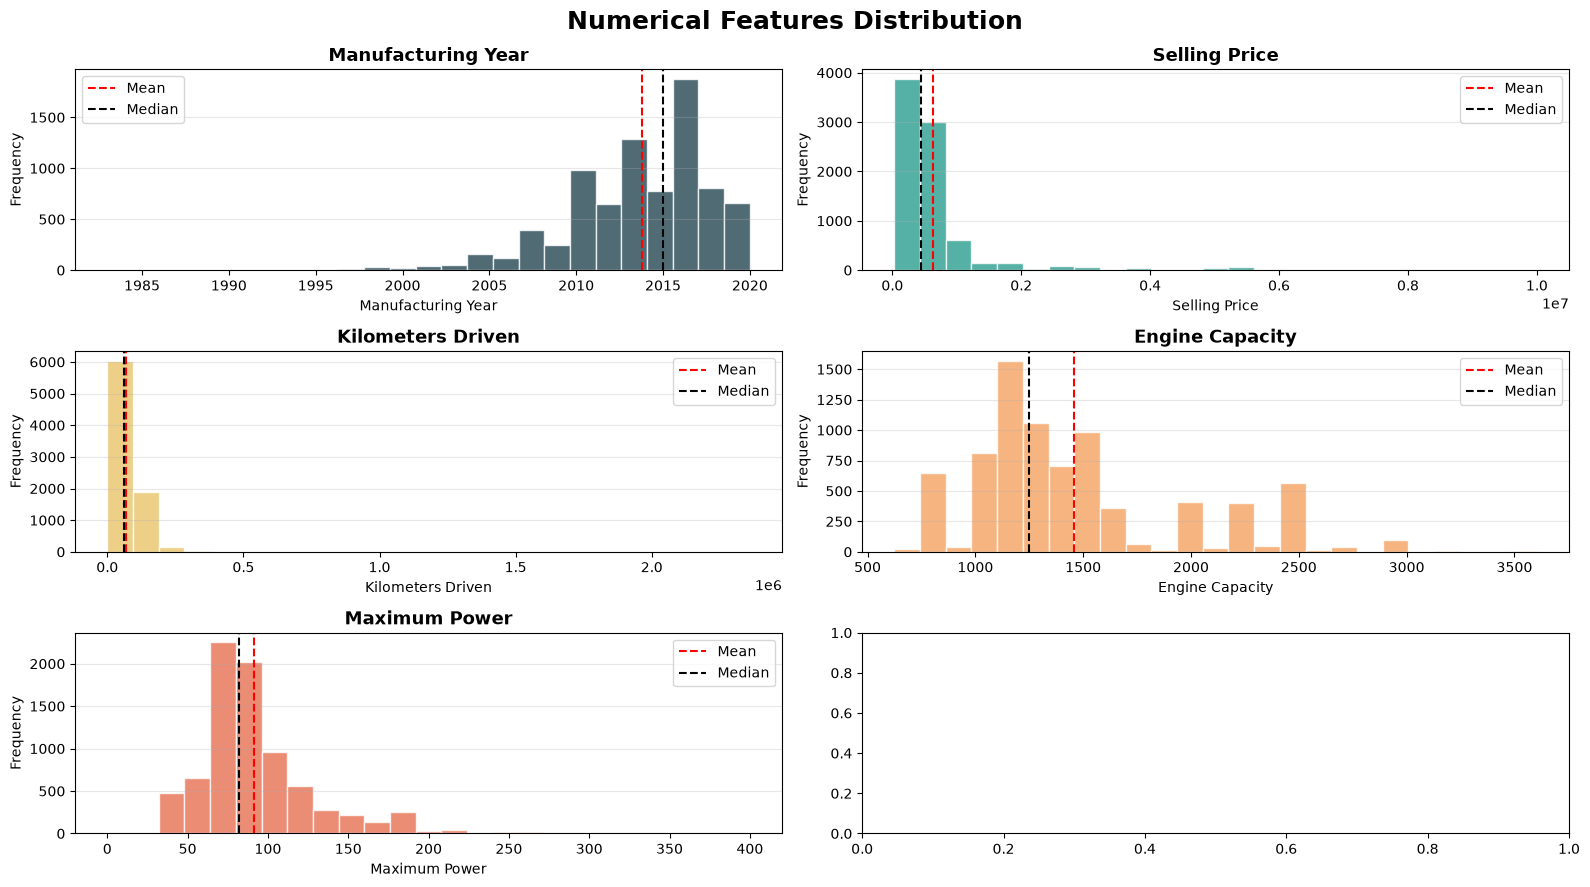

In [62]:
numerical = ['year', 'selling_price', 'km_driven','engine', 'max_power']
titles = ['Manufacturing Year', 'Selling Price','Kilometers Driven', 'Engine Capacity','Maximum Power']
colors = ['#264653', '#2A9D8F', '#E9C46A','#F4A261', '#E76F51']
fig, axes = plt.subplots(3, 2, figsize=(16, 9))
for ax, col, title, color in zip(axes.flatten(), numerical, titles, colors):
    ax.hist(df_eda[col].dropna(), bins=25,color=color, edgecolor='white', alpha=0.8)
    ax.axvline(df_eda[col].mean(),color='red', linestyle='--', label='Mean')
    ax.axvline(df_eda[col].median(),color='black', linestyle='--', label='Median')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel(title)
    ax.set_ylabel('Frequency')
    ax.grid(axis='y', alpha=0.3)
    ax.legend()

fig.suptitle('Numerical Features Distribution',fontsize=18, fontweight='bold')
fig.tight_layout()
plt.show()

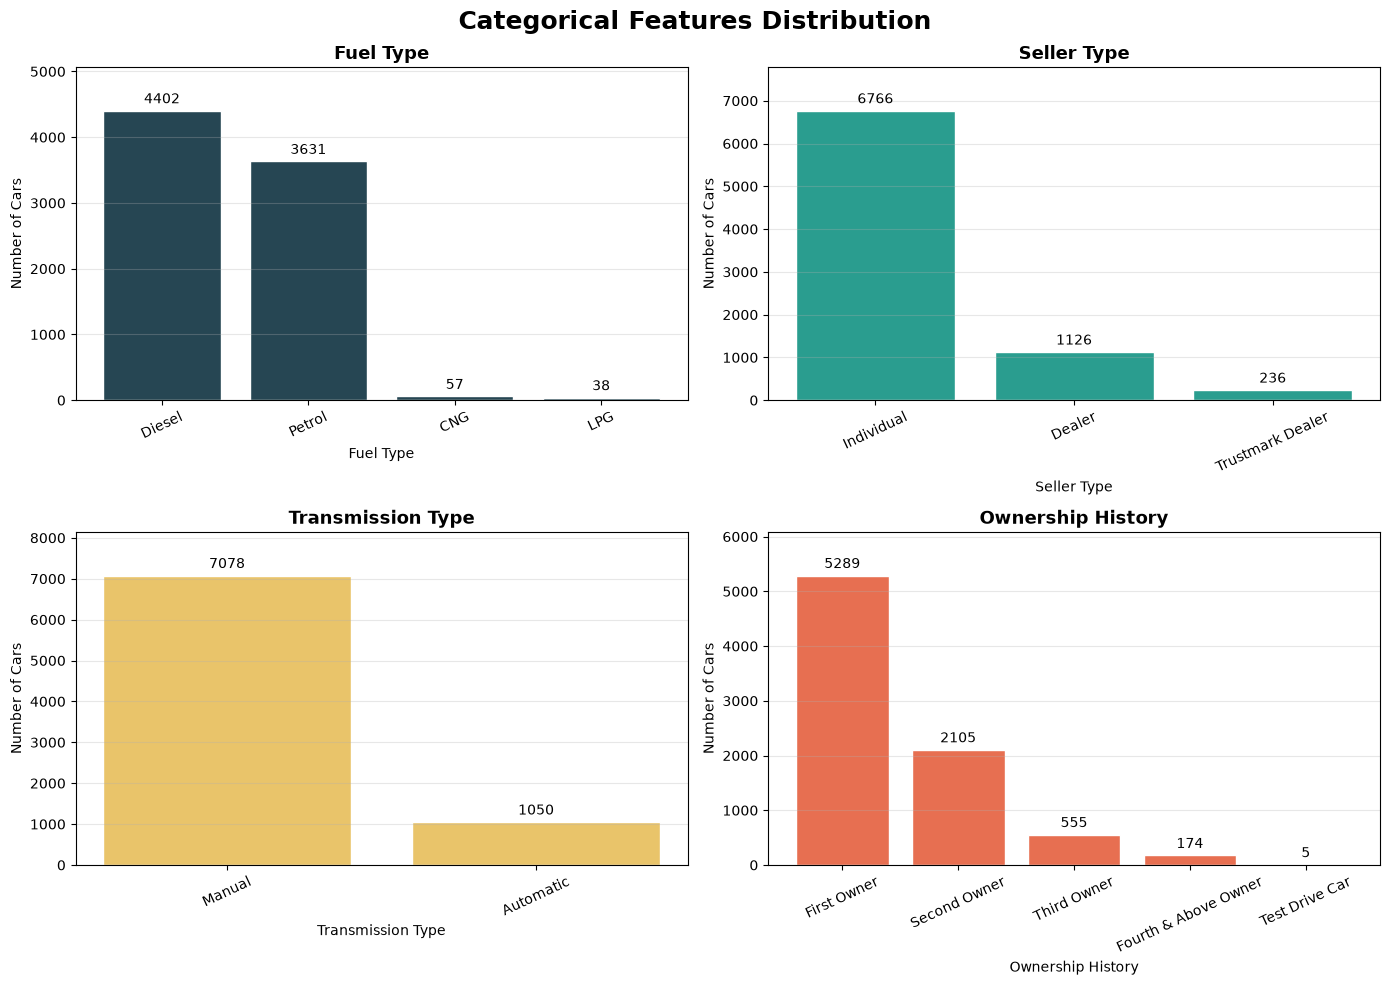

In [63]:
columns = ['fuel', 'seller_type','transmission', 'owner']
titles = ['Fuel Type', 'Seller Type','Transmission Type', 'Ownership History']
colors = ['#264653', '#2A9D8F','#E9C46A', '#E76F51']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col, title, color in zip(axes.flatten(), columns, titles, colors):
    counts = df_eda[col].value_counts()
    bars = ax.bar(counts.index, counts.values,color=color, edgecolor='white')
    ax.bar_label(bars, padding=3)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel(title)
    ax.set_ylabel('Number of Cars')
    ax.set_ylim(0, counts.max() * 1.15)
    ax.tick_params(axis='x', rotation=25)
    ax.grid(axis='y', alpha=0.3)

fig.suptitle('Categorical Features Distribution',fontsize=18, fontweight='bold')

fig.tight_layout()
plt.show()

In [67]:
torque = df_eda['torque'].str.lower()
df_eda['torque_nm'] = pd.to_numeric(torque.str.extract(r'(\d+\.?\d*)')[0])
df_eda.loc[torque.str.contains('kgm') & ~torque.str.contains('nm'), 'torque_nm'] *= 9.80665
df_eda.loc[~torque.str.contains('nm') & ~torque.str.contains('kgm'), 'torque_nm'] = np.nan
display(df_eda[['torque', 'torque_nm']].head(10))

,torque,torque_nm
0,190Nm@ 2000rpm,190.000000
1,250Nm@ 1500-2500rpm,250.000000
2,"12.7@ 2,700(kgm@ rpm)",124.544455
3,22.4 kgm at 1750-2750rpm,219.668960
4,"11.5@ 4,500(kgm@ rpm)",112.776475
5,113.75nm@ 4000rpm,113.750000
6,"7.8@ 4,500(kgm@ rpm)",76.491870
7,59Nm@ 2500rpm,59.000000
8,170Nm@ 1800-2400rpm,170.000000
9,160Nm@ 2000rpm,160.000000


In [66]:
rpm = df_eda['torque'].str.lower().str.replace(',', '')
rpm = rpm.str.extract(r'(?:@|\bat\b|/)\s*(\d+)(?:\s*[-~]\s*(\d+))?').astype(float)
df_eda['torque_rpm'] = rpm.mean(axis=1)
display(df_eda[['torque', 'torque_nm', 'torque_rpm']].head(10))

,torque,torque_nm,torque_rpm
0,190Nm@ 2000rpm,190.000000,2000.0
1,250Nm@ 1500-2500rpm,250.000000,2000.0
2,"12.7@ 2,700(kgm@ rpm)",124.544455,2700.0
3,22.4 kgm at 1750-2750rpm,219.668960,2250.0
4,"11.5@ 4,500(kgm@ rpm)",112.776475,4500.0
5,113.75nm@ 4000rpm,113.750000,4000.0
6,"7.8@ 4,500(kgm@ rpm)",76.491870,4500.0
7,59Nm@ 2500rpm,59.000000,2500.0
8,170Nm@ 1800-2400rpm,170.000000,2100.0
9,160Nm@ 2000rpm,160.000000,2000.0


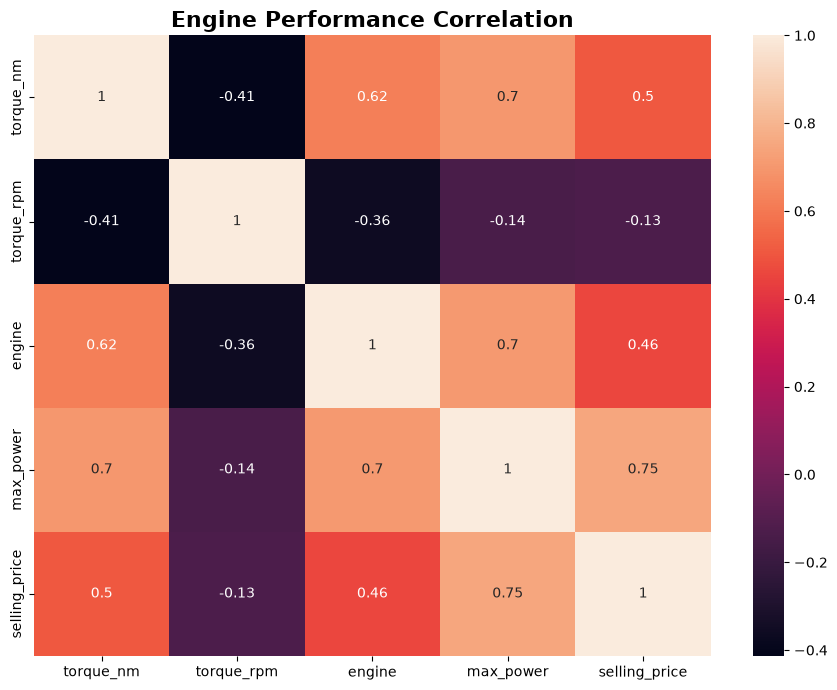

In [74]:
columns = ['torque_nm', 'torque_rpm','engine', 'max_power','selling_price']
corr = df_eda[columns].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr,ax=ax,annot=True)
ax.set_title('Engine Performance Correlation',fontsize=16, fontweight='bold')

fig.tight_layout()
plt.show()

In [86]:
columns = ['torque_nm', 'torque_rpm']
display(df_eda[columns].describe())
for col in columns:
    rate = df_eda[col]
    q1 = rate.quantile(0.25)
    q3 = rate.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    print(col)
    print("Lower bound:", lower)
    print("Upper bound:", upper)
    print("How many outliers exist?", ((rate < lower) | (rate > upper)).sum())
    display(df_eda[((rate < lower) | (rate > upper))])

,torque_nm,torque_rpm
count,7894.000000,7872.000000
mean,180.484459,2889.808626
std,109.197478,991.751459
min,47.071920,1300.000000
25%,111.800000,2000.000000
50%,170.000000,2400.000000
75%,209.000000,4000.000000
max,1863.263500,21800.000000


torque_nm
Lower bound: -34.000000000000014
Upper bound: 354.8
How many outliers exist? 431


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,mileage_unit,torque_nm,torque_rpm
51,Mitsubishi Pajero Sport 4X4,2013,1090000,151000,Diesel,Dealer,Manual,First Owner,13.50,2477.0,175.56,400Nm@ 2000-2500rpm,7.0,kmpl,400.0,2250.0
55,Toyota Innova Crysta 2.8 ZX AT BSIV,2016,1650000,127700,Diesel,Dealer,Automatic,Second Owner,11.36,2755.0,171.50,360Nm@ 1200-3400rpm,7.0,kmpl,360.0,2300.0
57,Audi A6 2.0 TDI Technology,2013,1750000,33900,Diesel,Dealer,Automatic,Second Owner,17.68,1968.0,174.33,380Nm@ 1750-2500rpm,5.0,kmpl,380.0,2125.0
59,Audi A6 2.0 TDI Design Edition,2013,1689999,50000,Diesel,Dealer,Automatic,First Owner,18.53,1968.0,187.74,400Nm@ 1750-3000rpm,5.0,kmpl,400.0,2375.0
60,Mercedes-Benz New C-Class 220 CDI AT,2013,1425000,59000,Diesel,Dealer,Automatic,First Owner,14.84,2143.0,170.00,400Nm@ 1400-2800rpm,5.0,kmpl,400.0,2100.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7920,Tata Hexa XT,2017,1400000,70000,Diesel,Individual,Manual,First Owner,17.60,2179.0,153.86,400Nm@ 1750-2500rpm,7.0,kmpl,400.0,2125.0
7930,Volvo S90 D4 Inscription BSIV,2019,5500000,17000,Diesel,Individual,Automatic,First Owner,18.00,1969.0,190.00,400Nm,5.0,kmpl,400.0,NaN
7931,Ford Endeavour 2.2 Titanium AT 4X2,2016,2100000,85000,Diesel,Individual,Automatic,Second Owner,12.62,2198.0,158.00,385Nm@ 1600-2500rpm,7.0,kmpl,385.0,2050.0
7967,BMW 3 Series 320d Sedan,2011,1500000,84925,Diesel,Individual,Automatic,First Owner,16.07,1995.0,181.00,380Nm@ 1750-3000rpm,5.0,kmpl,380.0,2375.0


torque_rpm
Lower bound: -1000.0
Upper bound: 7000.0
How many outliers exist? 1


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,mileage_unit,torque_nm,torque_rpm
5415,Tata Sumo EX TC,2005,225000,188000,Diesel,Individual,Manual,First Owner,12.3,1948.0,90.0,"190@ 21,800(kgm@ rpm)",7.0,kmpl,1863.2635,21800.0


In [84]:
df_eda.columns.tolist()

['name',
 'year',
 'selling_price',
 'km_driven',
 'fuel',
 'seller_type',
 'transmission',
 'owner',
 'mileage',
 'engine',
 'max_power',
 'torque',
 'seats',
 'mileage_unit',
 'torque_nm',
 'torque_rpm']

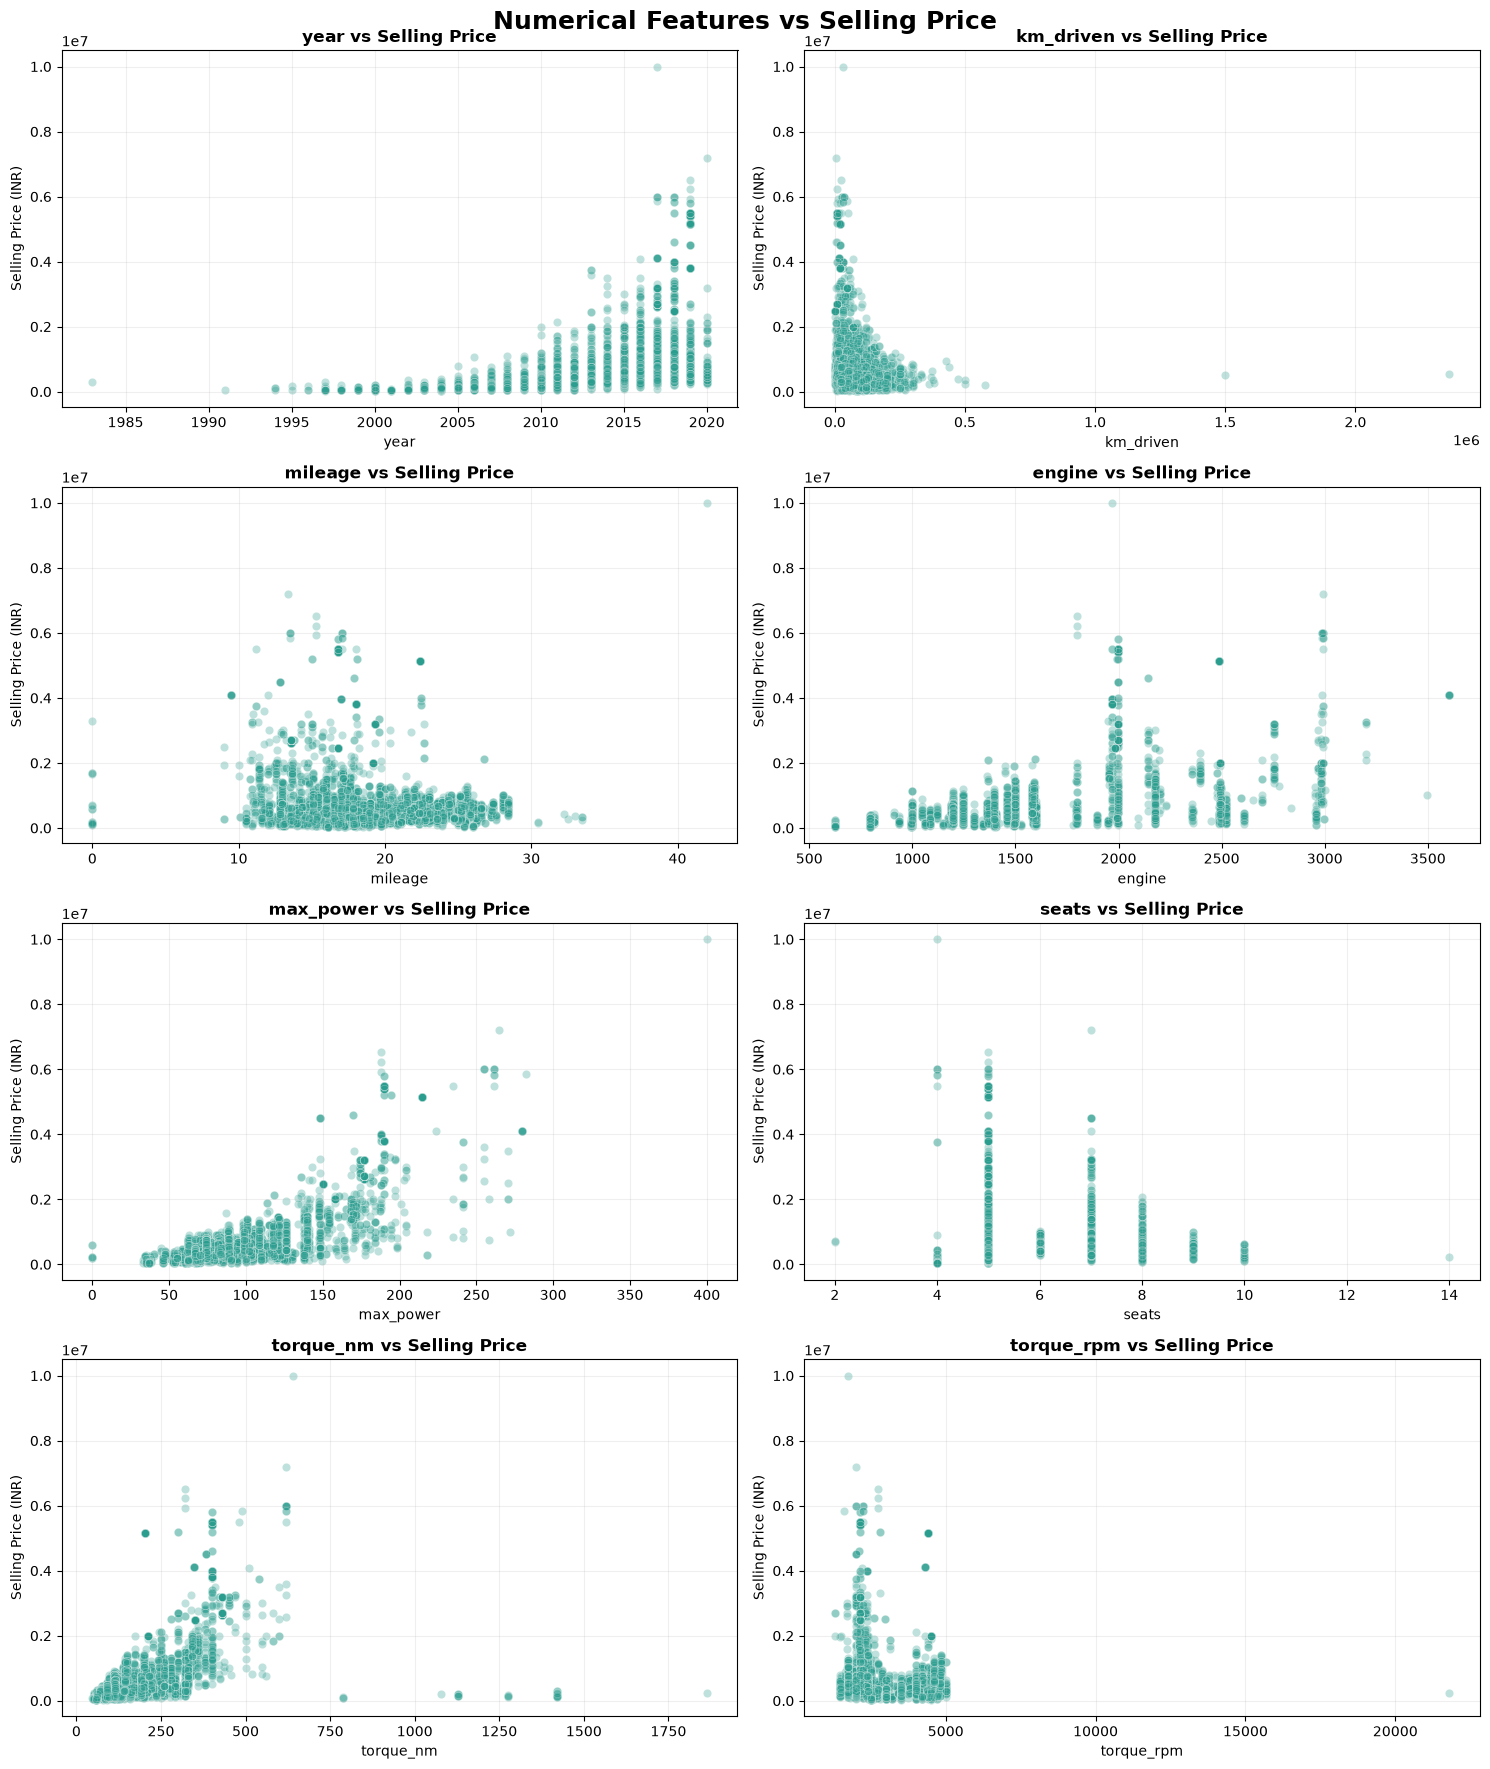

In [88]:
numerical = ['year', 'km_driven', 'mileage','engine', 'max_power', 'seats','torque_nm', 'torque_rpm']
fig, axes = plt.subplots(4, 2, figsize=(15, 18))
for col, ax in zip(numerical, axes.flatten()):
    sns.scatterplot(data=df_eda,x=col,y='selling_price',alpha=0.3,color='#2A9D8F',ax=ax)
    ax.set_title(f'{col} vs Selling Price', fontweight='bold')
    ax.set_ylabel('Selling Price (INR)')
    ax.grid(alpha=0.2)

fig.suptitle('Numerical Features vs Selling Price',fontsize=18, fontweight='bold')
fig.tight_layout()
plt.show()

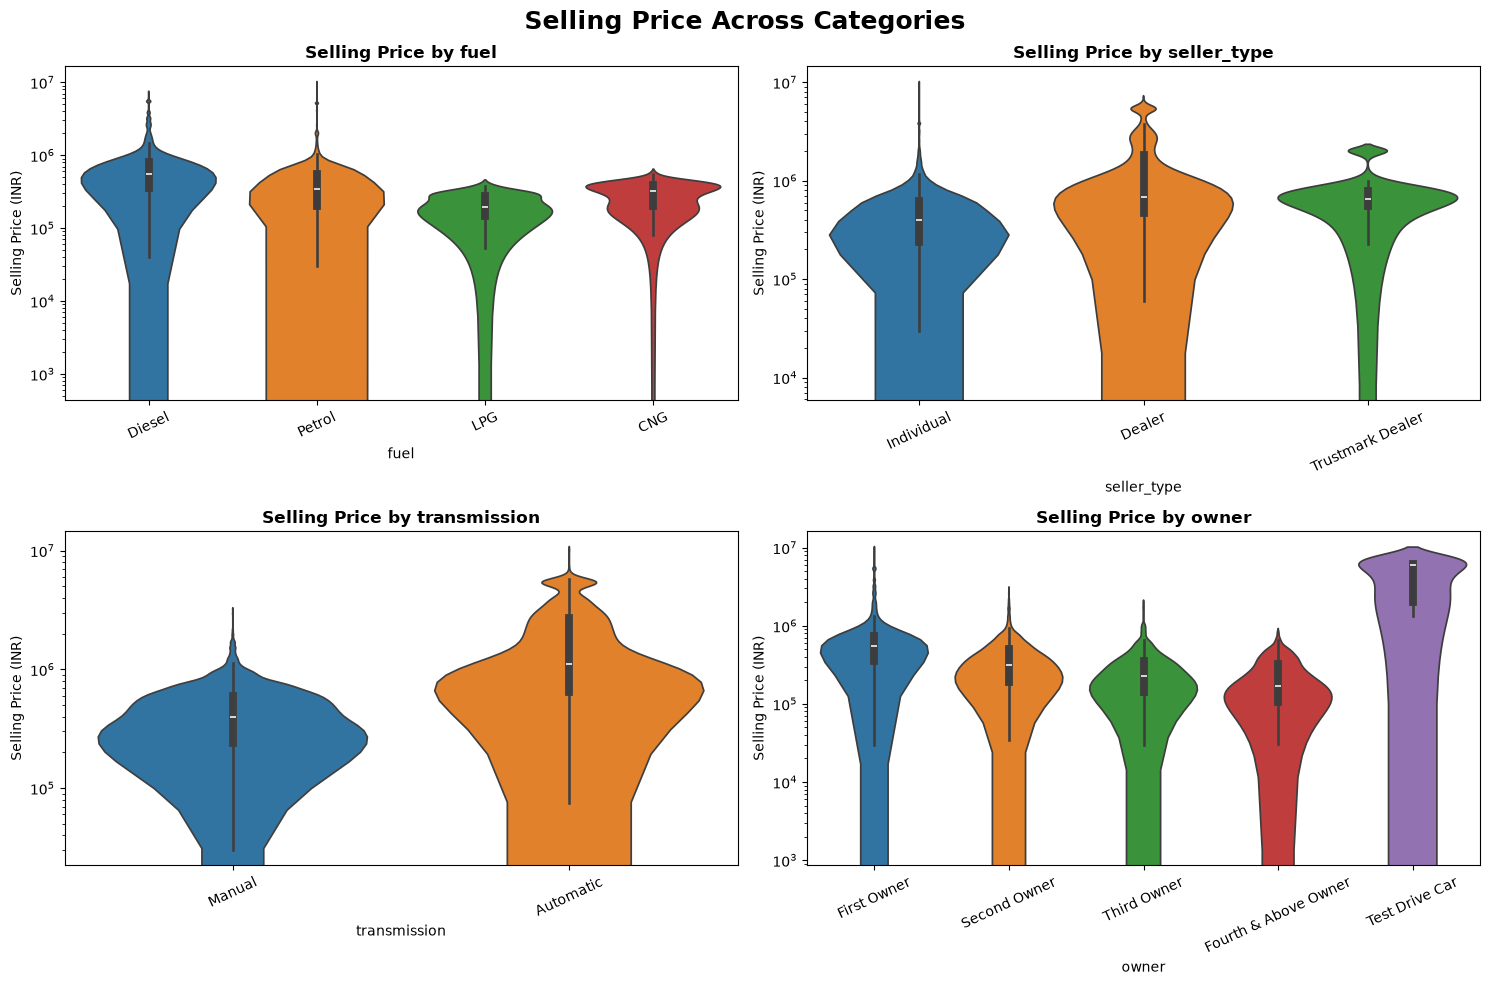

In [99]:
categorical = ['fuel', 'seller_type','transmission', 'owner']
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for col, ax in zip(categorical, axes.flatten()):
    sns.violinplot(data=df_eda,x=col, y='selling_price',hue=col,ax=ax)
    ax.set_title(f'Selling Price by {col}', fontweight='bold')
    ax.set_ylabel('Selling Price (INR)')
    ax.tick_params(axis='x', labelrotation=25)
    ax.set_yscale('log')

fig.suptitle('Selling Price Across Categories',fontsize=18, fontweight='bold')
fig.tight_layout()
plt.show()

In [114]:
df_eda['brand'] = df_eda['name'].str.split().str[0]
df_eda['brand'].value_counts()
brand_stats = df_eda.groupby('brand')['selling_price'].agg(['count' , 'mean'])
brand_stats = brand_stats.sort_values('count')
display(brand_stats)

,count,mean
brand,,
Ashok,1,3.000000e+05
Peugeot,1,5.700000e+04
Opel,1,6.800000e+04
Daewoo,3,7.700000e+04
MG,3,1.783333e+06
Ambassador,4,1.240000e+05
Kia,4,1.504500e+06
Isuzu,5,1.942000e+06
Land,6,3.608333e+06


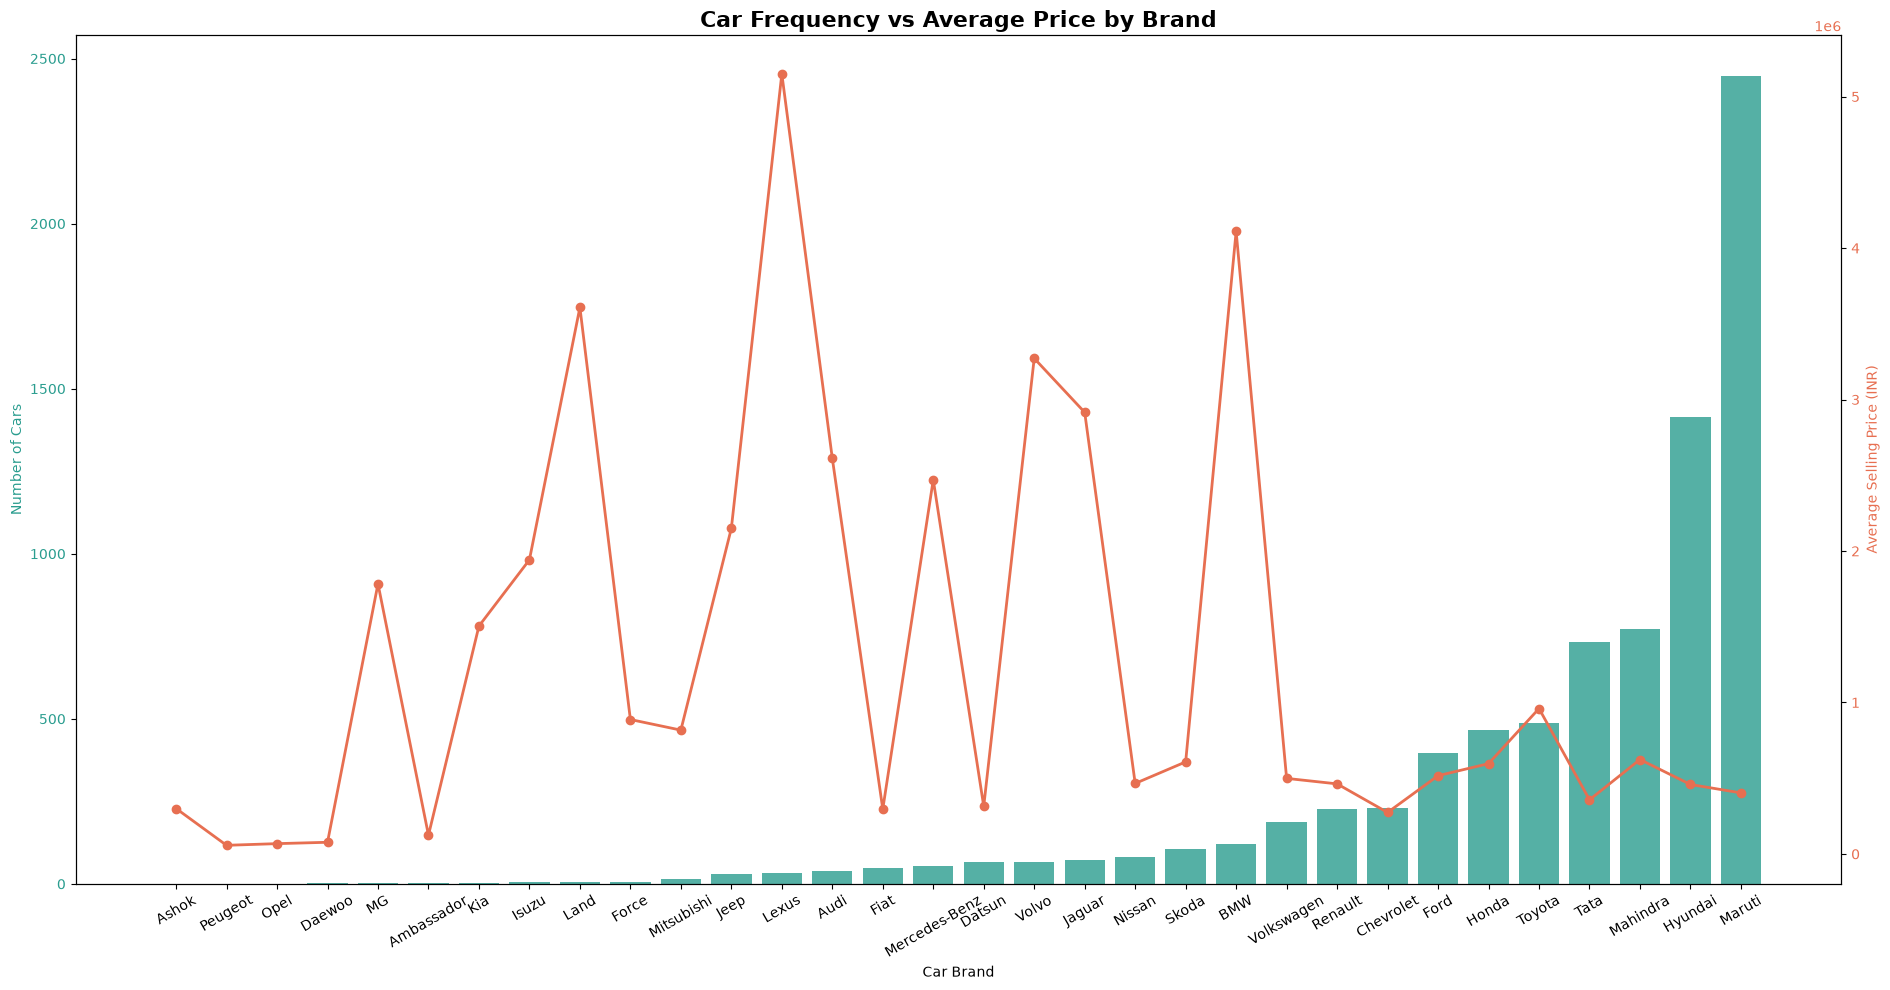

In [117]:
fig, ax = plt.subplots(figsize=(19, 10))
ax.bar(brand_stats.index, brand_stats['count'],color='#2A9D8F', alpha=0.8)
ax.set_xlabel('Car Brand')
ax.set_ylabel('Number of Cars', color='#2A9D8F')
ax.tick_params(axis='y', labelcolor='#2A9D8F')
ax.tick_params(axis='x', labelrotation=30)

ax2 = ax.twinx()
ax2.plot(brand_stats.index, brand_stats['mean'],color='#E76F51', marker='o', linewidth=2)
ax2.set_ylabel('Average Selling Price (INR)', color='#E76F51')
ax2.tick_params(axis='y', labelcolor='#E76F51')
ax.set_title('Car Frequency vs Average Price by Brand',fontsize=16, fontweight='bold')

fig.tight_layout()
plt.show()